**Human Movement Intelligence | Multimodal Movement Learning | Presented by: Reza Saadatyar (2026)**

**04 | Participant-Grouped Multimodal Fusion and Sensor Perturbation**

![Matched sEMG–acceleration inputs, independent fusion models and participant-level Development evaluation](../../images/04_fusion_and_modality_ablations.svg)

**Research question:** Does source-aligned acceleration improve movement recognition over the strongest unimodal method when both are assessed on the same unseen Development participants?

**Inputs:** Notebook 02's fixed E1 paired windows and participant-disjoint folds, and Notebook 03's matching original out-of-fold class probabilities.

**Methods:** Matched early feature fusion, fixed-weight classical/neural decision fusion and separately trained CNN, TCN, gated and compact cross-attention fusion. Synthetic acceleration replacements probe perturbation sensitivity, not real sensor failures.

**Primary metric:** Fixed-class macro F1 per unseen Development participant, averaged equally across people. All Test participants remain reserved for Notebook 05.


**00. Colab Repository Setup**


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("multimodal_movement_learning")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

# -------------------- 4. Deep Learning and Compute Device --------------------
from core.computer_device import computer_device
device = computer_device(min_vram_gb=None)

# ------------------------ 5. Research Model Utilities ------------------------
from ninapro_dataset import ensure_numerical_cache
from ninapro_evaluation import (
    select_model, per_class_oof_report, predictions_from_probabilities,
)
from sklearn.metrics import confusion_matrix
from ninapro_models import FUSION_MODELS, UNIMODAL_MODELS
from ninapro_fusion_experiments import (
    load_unimodal_oof, run_early_fusion_arm, run_fixed_late_arm,
    run_neural_fusion_arm, consolidate_fusion_outputs,
    evaluate_fusion_finalist_seeds, PERTURBATIONS,
)

# --------------------- 6. Canonical Study File Locations ---------------------
study_dir = root / "multimodal_movement_learning"
output_dir = study_dir / "output"
processed_dir = root / "data" / "processed" / "ninapro_db2"
output_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)


Repository up to date.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Research output directory: /content/human-movement-intelligence/multimodal_movement_learning/output


**02. Read Matched Development Windows and Notebook 03 Evidence**

Read the original Notebook 02 source-window identities, fixed corrected classes and participant-disjoint Development folds. The five reserved Test participants are excluded from model fitting and Development selection.

Decision-level fusion requires the **original Notebook 03 out-of-fold soft probabilities**. The repository tracks the matching keyed prediction CSV files but excludes `.npz` files. Before running this notebook in a new Colab environment, place the original `multimodal_movement_learning_Notebook_03_Outputs.zip` at `/content/`, or restore `03_oof_probabilities.npz` to `multimodal_movement_learning/output/`. The loader checks the actual class probabilities against all eleven model-specific window keys, fold assignments and predictions. Predicted class labels are not substituted for missing probabilities.


In [3]:
# ============ 02. Read Matched Development and Unimodal Evidence =============

# ------------------- 1. Fixed Source and Label Definitions -------------------
NOTEBOOK_NUMBER = 4
SEED = 42
index = pd.read_csv(output_dir / "02_window_index.csv")
roles = pd.read_csv(output_dir / "02_participant_split_assignments.csv")
folds = pd.read_csv(output_dir / "02_development_fold_assignments.csv")
classes = np.sort(
    pd.read_csv(output_dir / "01_label_dictionary.csv").label.to_numpy(int)
)
index["role"] = index.subject_id.map(
    dict(zip(roles.subject_id, roles.role))
)
index["validation_fold"] = index.subject_id.map(
    dict(zip(folds.subject_id, folds.validation_fold))
)
if index.role.isna().any():
    raise ValueError("Missing frozen Development/Test participant assignment.")
dev = index.loc[index.role == "Development"].copy()
test = index.loc[index.role == "Test"].copy()
if dev.empty or test.empty:
    raise ValueError("Development and reserved Test participants are required.")
if set(dev.subject_id) & set(test.subject_id):
    raise ValueError("Development and Test participants overlap.")
if dev.validation_fold.isna().any() or not index.window_key.is_unique:
    raise ValueError("Participant-fold or paired-window identity mismatch.")
common_folds = sorted(dev.validation_fold.unique().astype(int).tolist())

# ----------------- 2. Notebook 03 Out-of-Fold Probabilities ------------------
unimodal_metrics = pd.read_csv(output_dir / "03_all_unimodal_metrics.csv")
previous = load_unimodal_oof(index, dev, classes, output_dir)
print(
    "Development participants:", dev.subject_id.nunique(),
    "| paired windows:", len(dev),
)
print("Validation people by fold:")
display(dev.groupby("validation_fold").subject_id.nunique().rename("participants"))
print("Reserved Test participants:", test.subject_id.nunique())


Loaded matched Notebook 03 probabilities for 11 models and 35 Development participants.
Development participants: 35 | paired windows: 35000
Validation people by fold:


,participants
validation_fold,
0.0,7
1.0,7
2.0,7
3.0,7
4.0,7


Reserved Test participants: 5


**03. Recover Paired Statistical and Temporal Representations**

Classical feature fusion concatenates 48 sEMG and 96 acceleration features from the same source-window identity. Neural fusion reads corresponding 12-channel sEMG and 36-column acceleration recordings from the released common time grid.

Existing compatible numerical inputs are reused; missing inputs are retrieved and constructed. Scaling and neural normalisation use Training participants only, while identifiers, corrected labels and repetition metadata are never predictive features.


In [4]:
# ========== 03. Recover Source-Aligned Features and Temporal Inputs ==========

emg_features, acc_features = ensure_numerical_cache(
    root, index, allow_source_download=True, verbose=True,
)
if not (
    len(emg_features) == len(acc_features) == len(index)
    and index.window_key.is_unique
):
    raise ValueError("Paired numerical inputs do not match Notebook 02.")
print("Early-fusion feature width:", emg_features.shape[1] + acc_features.shape[1])


Preparing paired sEMG and acceleration recordings...
Paired recordings ready for 40 participants.
Extracting statistical features from the paired windows...
Saved statistical features (55.2 s).
Early-fusion feature width: 144


**04. F1: Early-Fusion Logistic Regression**

A 144-dimensional paired feature vector combines the same 48 sEMG and 96 acceleration statistics per window. Scaling is fitted within each Training fold; all seven held-out people in the matching Validation fold contribute to macro F1.


In [5]:
# ================= 04. F1: Early-Fusion Logistic Regression ==================

# Participant-Grouped Model Fit
display(run_early_fusion_arm(
    "F1_logreg", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))


  F1_logreg | fold 1/5 | macro F1 0.1286
  F1_logreg | fold 2/5 | macro F1 0.1627
  F1_logreg | fold 3/5 | macro F1 0.1424
  F1_logreg | fold 4/5 | macro F1 0.2193
  F1_logreg | fold 5/5 | macro F1 0.1627
F1_logreg | mean participant Development macro F1: 0.1632


,validation_fold,participants,macro_f1
0,0,7,0.128565
1,1,7,0.162737
2,2,7,0.142419
3,3,7,0.219342
4,4,7,0.162748


**05. F1: Early-Fusion Random Forest**

A 120-tree class-weighted Random Forest uses the same paired feature vector. Its five participant-disjoint folds, class definitions and feature window identities match those of Logistic Regression.


In [6]:
# ==================== 05. F1: Early-Fusion Random Forest =====================

# Participant-Grouped Model Fit
display(run_early_fusion_arm(
    "F1_rf", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))


  F1_rf | fold 1/5 | macro F1 0.2144
  F1_rf | fold 2/5 | macro F1 0.2791
  F1_rf | fold 3/5 | macro F1 0.2668
  F1_rf | fold 4/5 | macro F1 0.2984
  F1_rf | fold 5/5 | macro F1 0.2562
F1_rf | mean participant Development macro F1: 0.2630


,validation_fold,participants,macro_f1
0,0,7,0.214444
1,1,7,0.279114
2,2,7,0.266849
3,3,7,0.298439
4,4,7,0.256213


**06. F2: Classical Logistic Regression Late Fusion**

The 0.5/0.5 decision average combines the independently obtained, class-aligned Notebook 03 sEMG and acceleration Logistic Regression probabilities. No outer Validation labels are used to fit or select the mixing weights.


In [7]:
# ============= 06. F2: Classical Logistic Regression Late Fusion =============

# Participant-Grouped Model Fit
display(run_fixed_late_arm(
    "F2_logreg", index, dev, previous, classes,
    output_dir=output_dir, folds=common_folds,
    emg_name="B1_logreg", acc_name="B2_logreg", seed=SEED,
))


F2_logreg: equal weights for B1_logreg and B2_logreg
F2_logreg | mean participant Development macro F1: 0.1646


,validation_fold,participants,macro_f1
0,0,7,0.123422
1,1,7,0.138127
2,2,7,0.162670
3,3,7,0.223994
4,4,7,0.174830


**07. F2: Classical Random Forest Late Fusion**

The Random Forest decision-level control averages the sEMG and acceleration Random Forest OOF probabilities with predeclared equal weights, preserving the original 18 source-class columns.


In [8]:
# ================ 07. F2: Classical Random Forest Late Fusion ================

# Participant-Grouped Model Fit
display(run_fixed_late_arm(
    "F2_rf", index, dev, previous, classes,
    output_dir=output_dir, folds=common_folds,
    emg_name="B1_rf", acc_name="B2_rf", seed=SEED,
))


F2_rf: equal weights for B1_rf and B2_rf
F2_rf | mean participant Development macro F1: 0.2462


,validation_fold,participants,macro_f1
0,0,7,0.207961
1,1,7,0.273378
2,2,7,0.257802
3,3,7,0.263463
4,4,7,0.228459


**08. F4: Neural Decision-Level Late Fusion**

Select the strongest sEMG-only and acceleration-only *neural* models independently using Notebook 03's Development participant-level scores. Combine their already saved OOF soft probabilities with fixed equal weights. Preserve their identities for a final refit only if this recipe is chosen.


In [9]:
# ================= 08. F4: Neural Decision-Level Late Fusion =================

# Participant-Grouped Model Fit
chosen_emg, _ = select_model(
    unimodal_metrics,
    [name for name in UNIMODAL_MODELS if "_emg_" in name],
)
chosen_acc, _ = select_model(
    unimodal_metrics,
    [name for name in UNIMODAL_MODELS if "_acc_" in name],
)
print("sEMG neural component:", chosen_emg)
print("Acceleration neural component:", chosen_acc)
display(run_fixed_late_arm(
    "F4_deep_late", index, dev, previous, classes,
    output_dir=output_dir, folds=common_folds,
    emg_name=chosen_emg, acc_name=chosen_acc, seed=SEED,
))


sEMG neural component: D1_emg_cnn
Acceleration neural component: D2_acc_tcn
F4_deep_late: equal weights for D1_emg_cnn and D2_acc_tcn
F4_deep_late | mean participant Development macro F1: 0.1407


,validation_fold,participants,macro_f1
0,0,7,0.108732
1,1,7,0.147522
2,2,7,0.134755
3,3,7,0.178337
4,4,7,0.134296


**09. Shared Neural Fusion Protocol**

Each neural fusion architecture is trained independently on the original paired windows using seed 42, five person-disjoint Development folds, at most ten epochs, patience three, and batch size 96. Checkpoint selection uses only an inner subset of Training people. Where GPU memory allows, the normalised paired windows are cached once per fold; otherwise, the streamed path is used. This changes data throughput, not scientific inputs or model architecture.


In [10]:
# ===================== 09. Shared Neural Fusion Protocol =====================

# Participant-Grouped Model Fit
NEURAL_EPOCHS = 10
NEURAL_PATIENCE = 3
NEURAL_BATCH_SIZE = 96

print("Neural fusion models:", ", ".join(FUSION_MODELS))
print("Independent Development folds:", common_folds)
print("Maximum epochs:", NEURAL_EPOCHS)
print("Batch size:", NEURAL_BATCH_SIZE)


Neural fusion models: F3_dual_cnn, F3_dual_tcn, F5_gated, F5_cross_attention
Independent Development folds: [0, 1, 2, 3, 4]
Maximum epochs: 10
Batch size: 96


**10. F3: Dual-Branch 1D-CNN**

Two separately parameterised 1D-CNN encoders process aligned sEMG and acceleration windows, then concatenate learned embeddings for fixed-class classification. Synthetic mean replacement is a stress test on the fitted model, not real missing-sensor validation.



Model: F3_dual_cnn | paired sEMG + acceleration | device: cuda | 5 Development folds

  Fold 1/5 | 28 Training people, 7 Validation people
  Paired cache: preparing 3.00 GiB of Training-normalised windows on CUDA...
  Paired cache ready in 38.6 s; reused across the fold's training epochs.
  Data loader: both | GPU-cached | workers=0 | pinned memory=False | batch size=96
  F3_dual_cnn | seed=42 | epoch 1/10 | loss=2.2041 | inner macro F1=0.1236 | train=3.2 s | inner validation=0.1 s | total=3.4 s
  F3_dual_cnn | seed=42 | epoch 2/10 | loss=1.5649 | inner macro F1=0.1032 | train=1.5 s | inner validation=0.1 s | total=1.6 s
  F3_dual_cnn | seed=42 | epoch 3/10 | loss=1.3326 | inner macro F1=0.0982 | train=1.3 s | inner validation=0.1 s | total=1.3 s
  F3_dual_cnn | seed=42 | epoch 4/10 | loss=1.2098 | inner macro F1=0.1084 | train=1.3 s | inner validation=0.1 s | total=1.4 s
  Fold 1 completed | macro F1 0.1245 | best epoch 1 | model fit 7.6 s

  Fold 2/5 | 28 Training people, 7 Validati

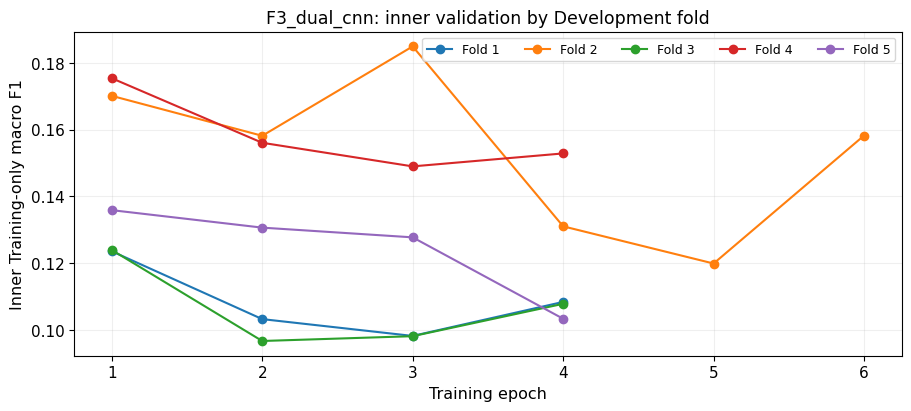

F3_dual_cnn | mean participant Development macro F1: 0.1499


,validation_fold,participants,macro_f1
0,0,7,0.124523
1,1,7,0.095720
2,2,7,0.173364
3,3,7,0.176319
4,4,7,0.179378


In [11]:
# ======================== 10. F3: Dual-Branch 1D-CNN =========================

# --------------------- 1. Participant-Grouped Model Fit ----------------------
display(run_neural_fusion_arm(
    "F3_dual_cnn", dev, processed_dir, classes,
    output_dir=output_dir, folds=common_folds, device=device,
    seed=SEED, epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**11. F3: Dual-Branch Temporal CNN**

Residual temporal convolutional encoders process each modality before a joint classification head. The same five unseen-person Development folds and Training-only early stopping govern this comparison.



Model: F3_dual_tcn | paired sEMG + acceleration | device: cuda | 5 Development folds

  Fold 1/5 | 28 Training people, 7 Validation people
  Paired cache: preparing 3.00 GiB of Training-normalised windows on CUDA...
  Paired cache ready in 27.7 s; reused across the fold's training epochs.
  Data loader: both | GPU-cached | workers=0 | pinned memory=False | batch size=96
  F3_dual_tcn | seed=42 | epoch 1/10 | loss=2.0770 | inner macro F1=0.1401 | train=2.8 s | inner validation=0.2 s | total=3.0 s
  F3_dual_tcn | seed=42 | epoch 2/10 | loss=1.4621 | inner macro F1=0.1227 | train=2.5 s | inner validation=0.2 s | total=2.7 s
  F3_dual_tcn | seed=42 | epoch 3/10 | loss=1.2604 | inner macro F1=0.1356 | train=2.6 s | inner validation=0.2 s | total=2.8 s
  F3_dual_tcn | seed=42 | epoch 4/10 | loss=1.1367 | inner macro F1=0.1455 | train=2.8 s | inner validation=0.2 s | total=3.0 s
  F3_dual_tcn | seed=42 | epoch 5/10 | loss=1.0652 | inner macro F1=0.1421 | train=2.5 s | inner validation=0.2 s 

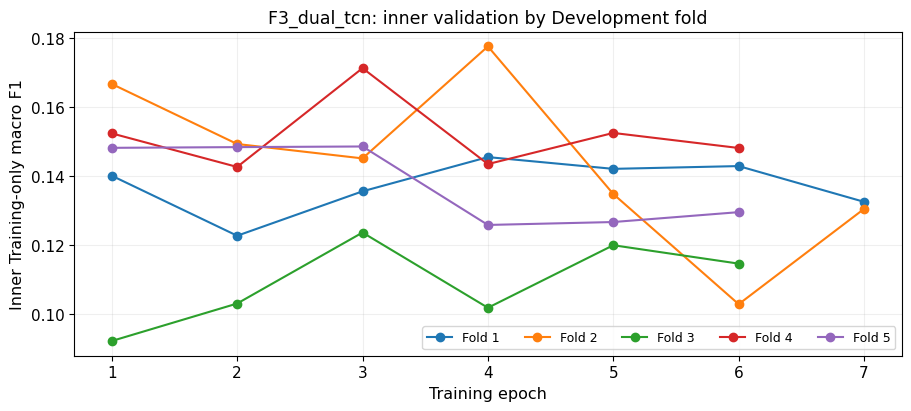

F3_dual_tcn | mean participant Development macro F1: 0.1546


,validation_fold,participants,macro_f1
0,0,7,0.121735
1,1,7,0.168382
2,2,7,0.151287
3,3,7,0.179844
4,4,7,0.151663


In [12]:
# ===================== 11. F3: Dual-Branch Temporal CNN ======================

# Participant-Grouped Model Fit
display(run_neural_fusion_arm(
    "F3_dual_tcn", dev, processed_dir, classes,
    output_dir=output_dir, folds=common_folds, device=device,
    seed=SEED, epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**12. F5: Gated Feature Fusion**

A learned gate combines the two temporal embeddings. The gating parameters and classification head are fitted on Training participants only. The gate's numerical weights do not constitute validated explanations.



Model: F5_gated | paired sEMG + acceleration | device: cuda | 5 Development folds

  Fold 1/5 | 28 Training people, 7 Validation people
  Paired cache: preparing 3.00 GiB of Training-normalised windows on CUDA...
  Paired cache ready in 28.2 s; reused across the fold's training epochs.
  Data loader: both | GPU-cached | workers=0 | pinned memory=False | batch size=96
  F5_gated | seed=42 | epoch 1/10 | loss=2.2607 | inner macro F1=0.1479 | train=1.5 s | inner validation=0.1 s | total=1.6 s
  F5_gated | seed=42 | epoch 2/10 | loss=1.6435 | inner macro F1=0.1400 | train=1.4 s | inner validation=0.1 s | total=1.4 s
  F5_gated | seed=42 | epoch 3/10 | loss=1.3966 | inner macro F1=0.1092 | train=1.3 s | inner validation=0.1 s | total=1.4 s
  F5_gated | seed=42 | epoch 4/10 | loss=1.2521 | inner macro F1=0.1420 | train=1.5 s | inner validation=0.1 s | total=1.5 s
  Fold 1 completed | macro F1 0.1487 | best epoch 1 | model fit 6.0 s

  Fold 2/5 | 28 Training people, 7 Validation people
  Pai

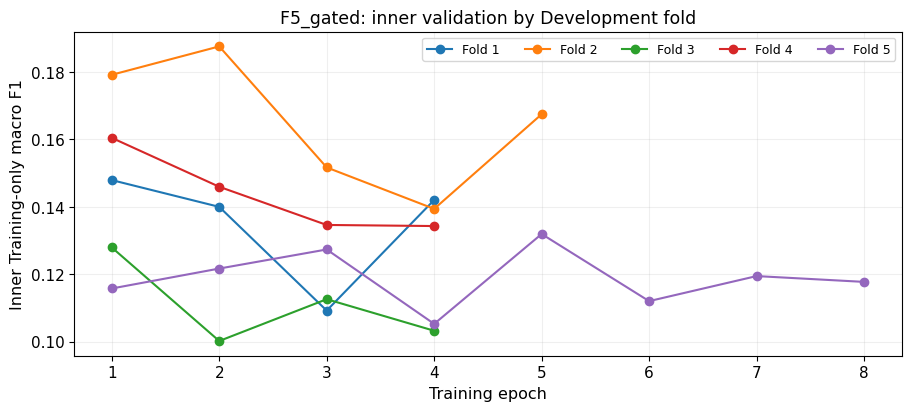

F5_gated | mean participant Development macro F1: 0.1402


,validation_fold,participants,macro_f1
0,0,7,0.148748
1,1,7,0.093194
2,2,7,0.151182
3,3,7,0.155498
4,4,7,0.152538


In [13]:
# ======================= 12. F5: Gated Feature Fusion ========================

# Participant-Grouped Model Fit
display(run_neural_fusion_arm(
    "F5_gated", dev, processed_dir, classes,
    output_dir=output_dir, folds=common_folds, device=device,
    seed=SEED, epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**13. F5: Compact Cross-Attention Fusion**

A compact two-head attention layer processes eight pooled temporal query/context tokens, with no external pretraining. Synthetic acceleration replacement is measured as an inference perturbation, not as a deployed sensor-failure test.



Model: F5_cross_attention | paired sEMG + acceleration | device: cuda | 5 Development folds

  Fold 1/5 | 28 Training people, 7 Validation people
  Paired cache: preparing 3.00 GiB of Training-normalised windows on CUDA...
  Paired cache ready in 27.4 s; reused across the fold's training epochs.
  Data loader: both | GPU-cached | workers=0 | pinned memory=False | batch size=96
  F5_cross_attention | seed=42 | epoch 1/10 | loss=2.1007 | inner macro F1=0.1683 | train=2.2 s | inner validation=0.1 s | total=2.3 s
  F5_cross_attention | seed=42 | epoch 2/10 | loss=1.5012 | inner macro F1=0.1353 | train=2.1 s | inner validation=0.1 s | total=2.1 s
  F5_cross_attention | seed=42 | epoch 3/10 | loss=1.2850 | inner macro F1=0.1515 | train=1.7 s | inner validation=0.1 s | total=1.8 s
  F5_cross_attention | seed=42 | epoch 4/10 | loss=1.1709 | inner macro F1=0.1425 | train=1.8 s | inner validation=0.1 s | total=1.9 s
  Fold 1 completed | macro F1 0.1001 | best epoch 1 | model fit 8.1 s

  Fold 2

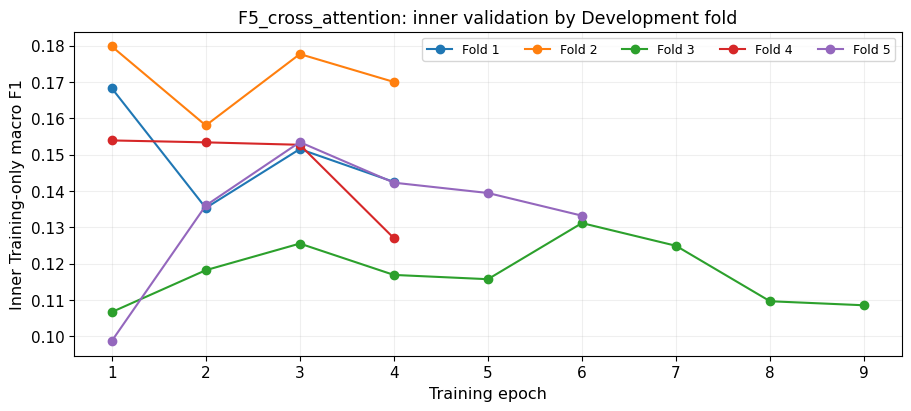

F5_cross_attention | mean participant Development macro F1: 0.1530


,validation_fold,participants,macro_f1
0,0,7,0.100054
1,1,7,0.127984
2,2,7,0.169112
3,3,7,0.189193
4,4,7,0.178853


In [14]:
# ================== 13. F5: Compact Cross-Attention Fusion ===================

# Participant-Grouped Model Fit
display(run_neural_fusion_arm(
    "F5_cross_attention", dev, processed_dir, classes,
    output_dir=output_dir, folds=common_folds, device=device,
    seed=SEED, epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**14. Consolidate Matched Development Fusion Evidence**

Each completed arm supplies model-specific OOF probabilities, keyed predictions and participant-level scores for all five independent Development folds. The consolidation rejects missing, incomplete or misaligned class labels and source-window identities rather than accepting partial results.

The Development-selected fusion recipe is compared against the strongest unimodal method from Notebook 03 using fixed-class macro F1 averaged equally across the same 35 people. Paired participant differences are reported without treating overlapping windows as independent participants. Reserved Test rows remain unpopulated.


In [15]:
# ============ 14. Consolidate Matched Development Fusion Evidence ============

# ------------------ 1. Read Complete Model-Specific Outputs ------------------
(best_unimodal, best_fusion, selection, u_summary, f_summary,
 paired_effects, robustness, fusion_metrics) = consolidate_fusion_outputs(
    index, dev, classes, unimodal_metrics, previous,
    output_dir=output_dir, folds=common_folds, seed=SEED,
    neural_settings={
        "epochs": NEURAL_EPOCHS,
        "patience": NEURAL_PATIENCE,
        "batch_size": NEURAL_BATCH_SIZE,
    },
    chosen_emg=chosen_emg, chosen_acc=chosen_acc,
)
print("Development-selected unimodal reference:", best_unimodal)
print("Development-selected fusion model:", best_fusion)
display(selection)
display(f_summary)


Loaded F1_logreg: 35 people
Loaded F1_rf: 35 people
Loaded F2_logreg: 35 people
Loaded F2_rf: 35 people
Loaded F4_deep_late: 35 people
Loaded F3_dual_cnn: 35 people
Loaded F3_dual_tcn: 35 people
Loaded F5_gated: 35 people
Loaded F5_cross_attention: 35 people
Development-selected unimodal reference: B1_rf
Development-selected fusion model: F1_rf


,selection_role,model_id,component_emg,component_acc
0,unimodal_comparator,B1_rf,,
1,fusion_comparator,F1_rf,,


,model_id,mean_subject_macro_f1,subjects
0,F1_rf,0.263012,35
1,F2_rf,0.246213,35
2,F2_logreg,0.164609,35
3,F1_logreg,0.163162,35
4,F3_dual_tcn,0.154582,35
5,F5_cross_attention,0.153039,35
6,F3_dual_cnn,0.149861,35
7,F4_deep_late,0.140728,35
8,F5_gated,0.140232,35


**15. Evaluate Additional Neural Fusion Seeds**

The strongest trained neural fusion architecture is selected using the original Development scores. It is then repeated with seeds 43 and 44 on the same person-disjoint folds. This checks training-seed variability, not generalisation to new people, and does not change the primary model selection.

Each additional seed/fold combination is saved separately. This experiment is independent of whether a classical or a neural fusion arm has the highest Development mean.


In [16]:
# ================ 15. Evaluate Additional Neural Fusion Seeds ================

# --------------------- 1. Select Neural Fusion Finalist ----------------------
EXTRA_SEEDS = (43, 44)
best_deep, _ = select_model(
    fusion_metrics, list(FUSION_MODELS),
)
print("Selected neural fusion architecture:", best_deep)

# ----------------------- 2. Repeat the Two Extra Seeds -----------------------
display(evaluate_fusion_finalist_seeds(
    best_deep, dev, processed_dir, classes,
    output_dir=output_dir, folds=common_folds, device=device,
    seeds=EXTRA_SEEDS, epochs=NEURAL_EPOCHS,
    patience=NEURAL_PATIENCE, batch_size=NEURAL_BATCH_SIZE,
))


Selected neural fusion architecture: F3_dual_tcn

F3_dual_tcn | additional seed 43 | fold 1/5
  Paired cache: preparing 3.00 GiB of Training-normalised windows on CUDA...
  Paired cache ready in 28.9 s; reused across the fold's training epochs.
  Data loader: both | GPU-cached | workers=0 | pinned memory=False | batch size=96
  F3_dual_tcn | seed=43 | epoch 1/10 | loss=2.0627 | inner macro F1=0.1461 | train=2.8 s | inner validation=0.2 s | total=3.0 s
  F3_dual_tcn | seed=43 | epoch 2/10 | loss=1.4524 | inner macro F1=0.1539 | train=2.7 s | inner validation=0.2 s | total=2.8 s
  F3_dual_tcn | seed=43 | epoch 3/10 | loss=1.2639 | inner macro F1=0.1340 | train=2.7 s | inner validation=0.2 s | total=2.8 s
  F3_dual_tcn | seed=43 | epoch 4/10 | loss=1.1621 | inner macro F1=0.1415 | train=2.8 s | inner validation=0.2 s | total=3.0 s
  F3_dual_tcn | seed=43 | epoch 5/10 | loss=1.0601 | inner macro F1=0.1417 | train=2.9 s | inner validation=0.2 s | total=3.1 s
  Additional seed 43, fold 1: ma

,seed,participant_mean_macro_f1,participants
0,43,0.119353,35
1,44,0.124863,35


**16. Compare Fusion Performance and Error Sensitivity**

The first figure contrasts the nine fusion candidates with the Notebook 03 unimodal benchmark using mean Development macro F1 per participant. The second shows the paired difference for every participant under the selected fusion configuration.

The third figure describes changes after **synthetic** replacement of acceleration channels with the Training mean in the fitted model. These experiments do not show observed physical sensor failures or learned missing-modality compensation. They remain Development diagnostics, not independent Test claims.

Class-wise diagnostics use the same existing OOF probabilities to report pooled-window and mean participant precision, recall and F1 for all nine fusion methods. A count-based and true-class-normalised confusion matrix, together with a class-F1 heatmap, make Rest imbalance and movement-specific failures visible. These summaries are Development-only and do not contribute new hyperparameter tuning.


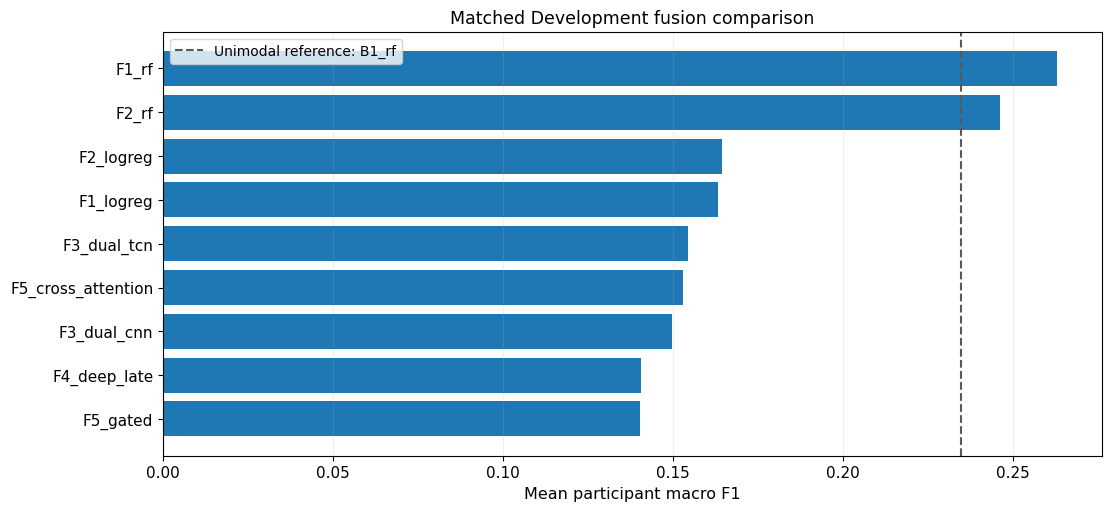

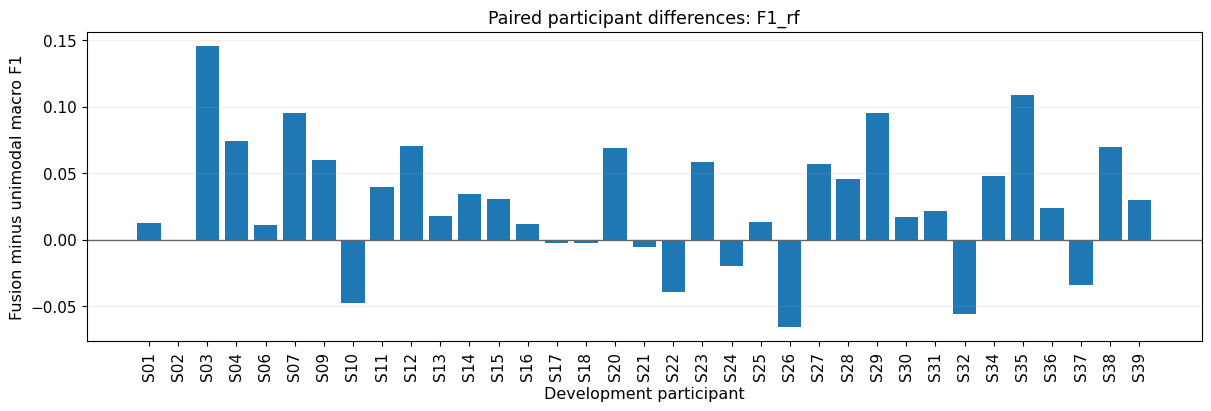

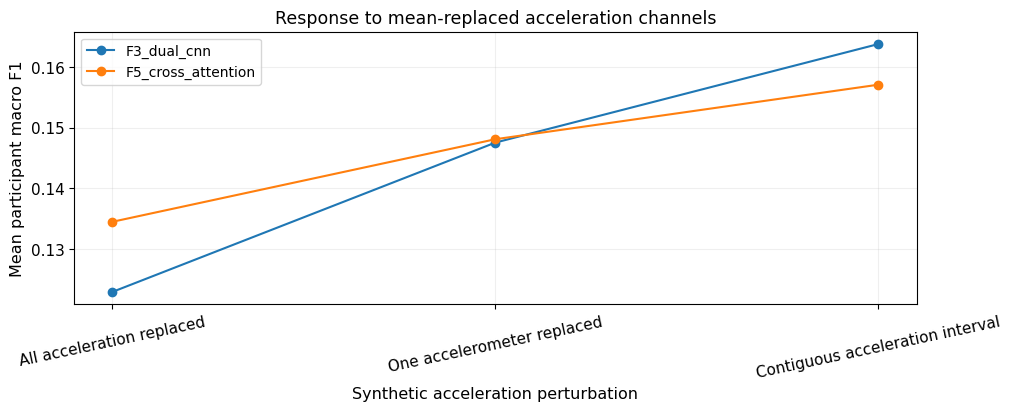

,class_label,support_windows,participants_with_support,pooled_precision,pooled_recall,pooled_f1,mean_participant_recall,mean_participant_f1
18,0,16329,35,0.6825,0.9422,0.7916,0.9442,0.7866
19,1,1464,35,0.3338,0.1571,0.2137,0.1545,0.1653
20,2,1279,35,0.1927,0.0790,0.1120,0.0855,0.0917
21,3,1124,35,0.1929,0.1299,0.1552,0.1535,0.1295
22,4,1098,35,0.2182,0.0546,0.0874,0.0677,0.0767
23,5,1117,35,0.2045,0.0573,0.0895,0.0714,0.0851
24,6,947,35,0.4328,0.2788,0.3391,0.3719,0.3604
25,7,1386,35,0.3771,0.0952,0.1521,0.0939,0.1335
26,8,1087,35,0.1984,0.0451,0.0735,0.0582,0.0573
27,9,1167,35,0.4232,0.4439,0.4333,0.4703,0.4385


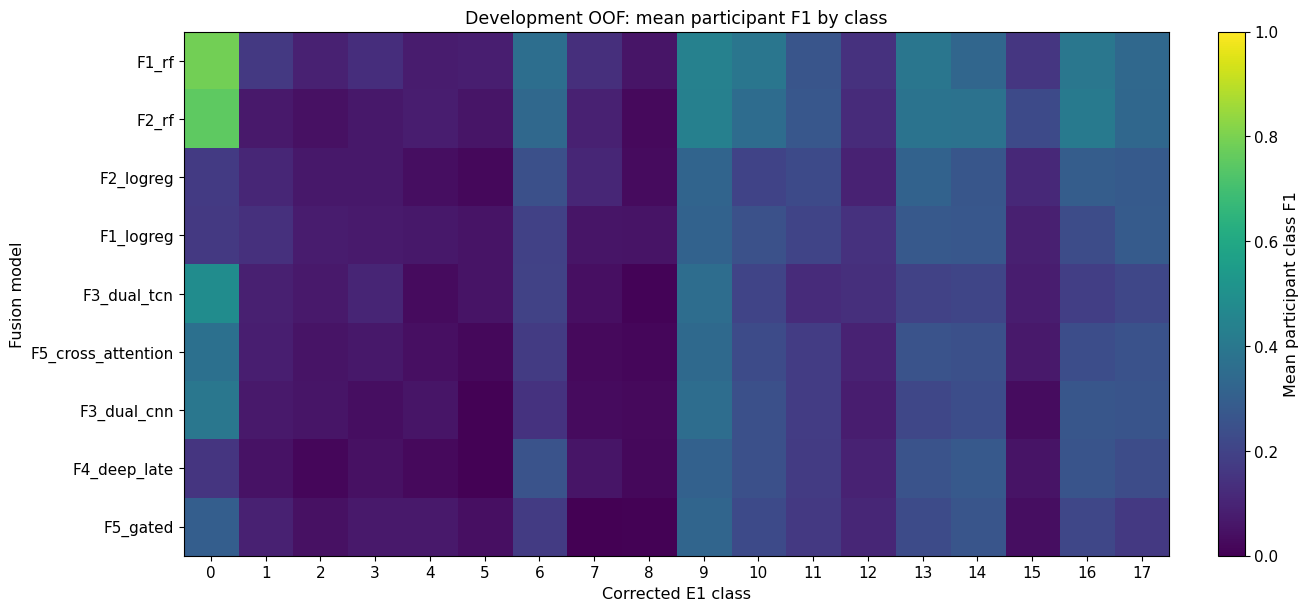

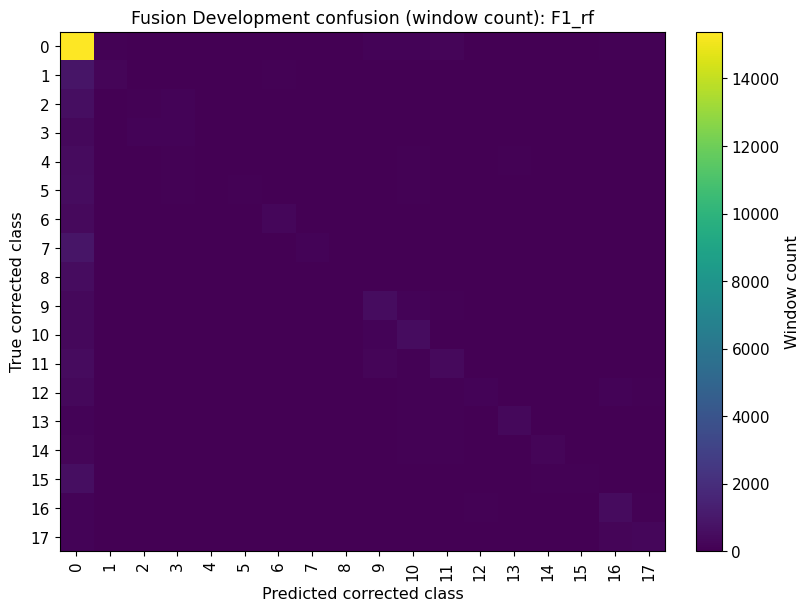

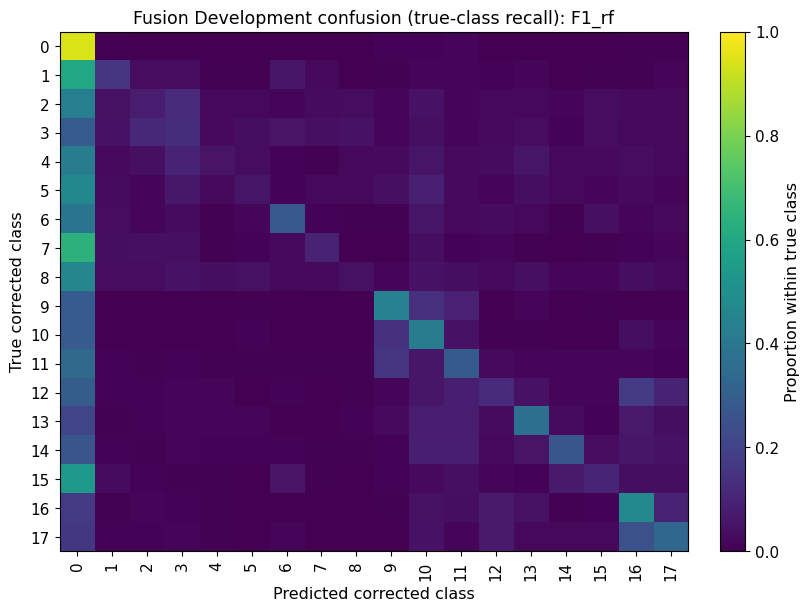

In [17]:
# =========== 16. Compare Fusion Performance and Error Sensitivity ============

# ------------------- 1. Participant-Balanced Fusion Scores -------------------
fig, ax = plt.subplots(figsize=(11, 5), layout="constrained")
order = f_summary.iloc[::-1]
ax.barh(order.model_id, order.mean_subject_macro_f1)
reference_score = float(
    u_summary.set_index("model_id").loc[
        best_unimodal, "mean_subject_macro_f1"
    ]
)
ax.axvline(
    reference_score, color="0.35", linestyle="--",
    label=f"Unimodal reference: {best_unimodal}",
)
ax.set(
    xlabel="Mean participant macro F1",
    title="Matched Development fusion comparison",
)
ax.grid(axis="x", alpha=0.2)
ax.legend()
save_figure(fig, output_dir / "04_fusion_comparison.png")
plt.show()

# --------------------- 2. Paired Participant Differences ---------------------
matched = paired_effects.loc[
    paired_effects.model_id == best_fusion
].sort_values("subject_id")
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.bar(
    matched.subject_id, matched.fusion_minus_unimodal_macro_f1,
)
ax.axhline(0, color="0.4", linewidth=1)
ax.set(
    xlabel="Development participant",
    ylabel="Fusion minus unimodal macro F1",
    title=f"Paired participant differences: {best_fusion}",
)
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.2)
save_figure(fig, output_dir / "04_subject_paired_differences.png")
plt.show()

# ------------------- 3. Synthetic Acceleration Replacement -------------------
labels = {
    "acc_missing_mean": "All acceleration replaced",
    "acc_sensor_01_missing_mean": "One accelerometer replaced",
    "acc_contiguous_gap_mean": "Contiguous acceleration interval",
}
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
for name, part in robustness.groupby("model_id", sort=True):
    means = part.groupby("perturbation").macro_f1.mean()
    settings = list(PERTURBATIONS)
    ax.plot(
        [labels[x] for x in settings],
        [float(means[x]) for x in settings],
        marker="o", label=name,
    )
ax.set(
    xlabel="Synthetic acceleration perturbation",
    ylabel="Mean participant macro F1",
    title="Response to mean-replaced acceleration channels",
)
ax.tick_params(axis="x", rotation=12)
ax.grid(alpha=0.2)
ax.legend()
save_figure(fig, output_dir / "04_modality_sensitivity.png")
plt.show()


# --------------------- 4. Per-Class OOF Fusion Evidence ----------------------
with np.load(
    output_dir / "04_oof_probabilities.npz", allow_pickle=False,
) as saved:
    all_fusion_probabilities = {
        model_id: saved[model_id] for model_id in saved.files
    }
source_rows = dev.sort_values("window_row").reset_index(drop=True)
source_positions = source_rows.window_row.to_numpy(int)
fusion_class_reports = []
for model_id, probability_matrix in all_fusion_probabilities.items():
    fusion_class_reports.append(per_class_oof_report(
        source_rows, probability_matrix[source_positions], classes,
        model_id=model_id,
    ))
fusion_class_metrics = pd.concat(fusion_class_reports, ignore_index=True)
fusion_class_metrics.to_csv(
    output_dir / "04_all_fusion_per_class_metrics.csv", index=False,
)
selected_fusion_class = fusion_class_metrics.loc[
    fusion_class_metrics.model_id == best_fusion
].copy()
selected_fusion_class.to_csv(
    output_dir / "04_selected_fusion_per_class_metrics.csv", index=False,
)
observed_f1 = float(selected_fusion_class.mean_participant_f1.mean())
expected_f1 = float(
    f_summary.set_index("model_id").loc[
        best_fusion, "mean_subject_macro_f1"
    ]
)
if not np.isclose(observed_f1, expected_f1, atol=1e-9):
    raise ValueError("Fusion class F1 and participant macro F1 disagree.")
display(selected_fusion_class[[
    "class_label", "support_windows", "participants_with_support",
    "pooled_precision", "pooled_recall", "pooled_f1",
    "mean_participant_recall", "mean_participant_f1",
]].round(4))

# ------------------- 5. Class-Wise Fusion Model Comparison -------------------
grid = (
    fusion_class_metrics.pivot(
        index="model_id", columns="class_label",
        values="mean_participant_f1",
    ).reindex(index=f_summary.model_id, columns=classes)
)
fig, ax = plt.subplots(figsize=(13, 6), layout="constrained")
im = ax.imshow(grid.to_numpy(), aspect="auto", vmin=0, vmax=1)
ax.set(
    xlabel="Corrected E1 class", ylabel="Fusion model",
    title="Development OOF: mean participant F1 by class",
)
ax.set_xticks(np.arange(len(classes)), labels=classes)
ax.set_yticks(np.arange(len(grid.index)), labels=grid.index)
fig.colorbar(im, ax=ax, label="Mean participant class F1")
save_figure(fig, output_dir / "04_fusion_per_class_f1_heatmap.png")
plt.show()

# ---------------------- 6. Fusion Confusion and Recall -----------------------
selected_probabilities = all_fusion_probabilities[best_fusion][source_positions]
matrix = confusion_matrix(
    source_rows.label.to_numpy(int),
    predictions_from_probabilities(selected_probabilities, classes),
    labels=classes,
)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
im = ax.imshow(matrix, aspect="auto")
ax.set(
    xlabel="Predicted corrected class", ylabel="True corrected class",
    title=f"Fusion Development confusion (window count): {best_fusion}",
)
ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
ax.set_yticks(np.arange(len(classes)), labels=classes)
fig.colorbar(im, ax=ax, label="Window count")
save_figure(fig, output_dir / "04_fusion_class_errors.png")
plt.show()

support = matrix.sum(axis=1, keepdims=True)
normalised = np.divide(
    matrix, support, out=np.zeros_like(matrix, dtype=float),
    where=support > 0,
)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
im = ax.imshow(normalised, aspect="auto", vmin=0, vmax=1)
ax.set(
    xlabel="Predicted corrected class", ylabel="True corrected class",
    title=f"Fusion Development confusion (true-class recall): {best_fusion}",
)
ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
ax.set_yticks(np.arange(len(classes)), labels=classes)
fig.colorbar(im, ax=ax, label="Proportion within true class")
save_figure(fig, output_dir / "04_fusion_class_errors_normalised.png")
plt.show()


**17. Research Output Files and Interpretation**

The named Notebook 04 outputs include fold-specific participant metrics, OOF prediction and probability arrays, neural training histories, synthetic perturbation scores, paired per-participant fusion differences, and the Development-only choice of the final fusion recipe.

The downloadable archive is generated outside the Git repository. It preserves the numerical evidence without adding large source arrays or model checkpoints to Git history. Notebook 05 evaluates the fixed Development-selected models on the separate reserved Test participants.


In [18]:
# =============== 17. Research Output Files and Interpretation ================

# ------------------------ 1. Notebook Output Archive -------------------------
download_outputs_from_colab(
    "multimodal_movement_learning/output",
    f"{NOTEBOOK_NUMBER:02d}",
)


------------------------------------------------------------------------
Notebook 04
Files packaged: 55
  + 04_F1_logreg_metrics.csv
  + 04_F1_logreg_oof_predictions.csv
  + 04_F1_logreg_oof_probabilities.npz
  + 04_F1_rf_metrics.csv
  + 04_F1_rf_oof_predictions.csv
  + 04_F1_rf_oof_probabilities.npz
  + 04_F2_logreg_metrics.csv
  + 04_F2_logreg_oof_predictions.csv
  + 04_F2_logreg_oof_probabilities.npz
  + 04_F2_rf_metrics.csv
  + 04_F2_rf_oof_predictions.csv
  + 04_F2_rf_oof_probabilities.npz
  + 04_F3_dual_cnn_learning_curve.png
  + 04_F3_dual_cnn_learning_history.csv
  + 04_F3_dual_cnn_metrics.csv
  + 04_F3_dual_cnn_oof_predictions.csv
  + 04_F3_dual_cnn_oof_probabilities.npz
  + 04_F3_dual_cnn_robustness.csv
  + 04_F3_dual_tcn_extra_seed_history.csv
  + 04_F3_dual_tcn_extra_seed_metrics.csv
  + 04_F3_dual_tcn_learning_curve.png
  + 04_F3_dual_tcn_learning_history.csv
  + 04_F3_dual_tcn_metrics.csv
  + 04_F3_dual_tcn_oof_predictions.csv
  + 04_F3_dual_tcn_oof_probabilities.npz
  + 